# Phase 1 reward-aligned experimental design

**SO reward (both policies):** `reward = DL_norm_post` (no improvement shaping). **MO reward (both policies):** `0.50*r_DL + 0.15*r_RSRP + 0.15*r_RSRQ + 0.10*r_RSSI + 0.08*r_CQI + 0.02*r_SNR`. There are **no proactive forecast bonuses or volume-preservation bonuses/penalties**. The Fused policy sees the ensemble forecast as an additional state input; Reactive does not. Both use the same six actions, action effects, training configuration, trace, normalization, and evaluation starts. Simulated normalized DL can exceed 1; KPI and discretization bounds remain as originally defined. The 20-segment results are within one RL training trace, not a held-out RL generalization experiment.

# Phase 1 — Reactive SO/MO Tabular Q-Learning (Independent Notebook)

Reactive-only RL training and 20-segment evaluation. This notebook **does not train forecasting models or use forecast predictions**. Run the Fused notebook once to export `phase1_rl_exports/shared_rl_trace.npz`, then run this notebook with that folder available. It uses the same environment transition/reward definitions as the Fused notebook but excludes the forecast from the policy state. Neither proactive nor volume-preservation bonuses are included. The two policies train from fresh Q-tables. Both are evaluated on the same single trace used for RL training, so results are in-sample.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
DATA_DIR=Path('phase1_rl_exports')
path=DATA_DIR/'shared_rl_trace.npz'
if not path.exists():
    raise FileNotFoundError(f'{path} missing: run Fused notebook export cell first and place the export folder alongside this notebook.')
with np.load(path) as data:
    y_te_aligned=data['y_te_aligned'].copy()
    cov_aligned=data['cov_aligned'].copy()
    lo_rl=float(data['lo_rl']); hi_rl=float(data['hi_rl'])
    cv_starts=data['cv_starts'].astype(int).copy()
    N_EP=int(data['N_EP']); RL_SEED=int(data['RL_SEED'])
    RL_TRAIN_STEPS=int(data['RL_TRAIN_STEPS'])
    SEG_LEN=int(data['SEG_LEN']); FIXED_START=int(data['FIXED_START'])
N_CV_SEGS=len(cv_starts)
N_SIM=min(200,len(y_te_aligned)-FIXED_START)
evaluation_overlap=any(cv_starts[i]+SEG_LEN>cv_starts[i+1] for i in range(len(cv_starts)-1))
print('Aligned observations:',len(y_te_aligned),'segment starts:',cv_starts.tolist())
print('Evaluation segments overlap:',evaluation_overlap)


Aligned observations: 1111 segment starts: [77, 79, 84, 116, 181, 388, 393, 410, 466, 475, 585, 627, 650, 665, 689, 691, 713, 765, 771, 881]
Evaluation segments overlap: True


## Identical simulated SO/MO environment dynamics and reward definitions

In [2]:

# Actions available to the RL agent
ACTIONS = ['Increase_TX_power', 'Adjust_beamforming', 'Optimise_MCS',
           'Reduce_interference', 'Increase_bandwidth', 'Load_balance']

# Covariate index map (order must match COVARIATES / the last 6 columns of Track A features)
COV_IDX = {'RSRP': 0, 'RSRQ': 1, 'SNR': 2, 'CQI': 3, 'RSSI': 4, 'Speed': 5}

# Single-Objective shared reward environment (Fused)
class SOEnvFused:
    """Single-objective with shared forecast-neutral reward: 
    reward = post-action normalized DL throughput only.
    Forecast affects the fused state only, never the reward."""
    
    DL_DELTAS = [0.08, 0.10, 0.12, 0.07, 0.09, 0.11]
    STEP_DURATION = 1.0

    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):
        self.yn, self.fc, self.cov = yn_te, fc, cov
        self.lo_rl, self.hi_rl = lo_rl, hi_rl
        self.N = len(yn_te)
        self.N_ACT = len(ACTIONS)
        self.bounds = ([(float(cov[:, i].min()), float(cov[:, i].max())) for i in range(cov.shape[1])]
                       + [(0., 1.), (0., 1.)])
        self.idx = 0
        self.cumulative_volume_pre_Mb = 0.0
        self.cumulative_volume_post_Mb = 0.0
        self.episode_start_idx = 0
        self.action_stats = {i: {'count': 0, 'total_reward': 0.0, 'success_count': 0,
                                  'total_improvement': 0.0} for i in range(self.N_ACT)}

    def reset(self, random_start=True):
        self.idx = np.random.randint(0, max(1, self.N - 51)) if random_start else 0
        self.episode_start_idx = self.idx
        self.cumulative_volume_pre_Mb = 0.0
        self.cumulative_volume_post_Mb = 0.0
        return self._state()

    def _state(self):
        c = self.cov[self.idx].astype(float)
        return np.concatenate([c, [float(self.yn[self.idx]), float(self.fc[self.idx])]])



    def step(self, action):
        i = self.idx
        dl = float(self.yn[i])
        dl_new = float(max(dl + self.DL_DELTAS[action], 0.))   # no upper clip: holdout DL may exceed the dev max (dev-only normalisation)
        dl_improvement = dl_new - dl

        dl_mbps_pre = dl * (self.hi_rl - self.lo_rl) + self.lo_rl
        dl_mbps_post = dl_new * (self.hi_rl - self.lo_rl) + self.lo_rl
        volume_pre_Mb = dl_mbps_pre * self.STEP_DURATION
        volume_post_Mb = dl_mbps_post * self.STEP_DURATION
        self.cumulative_volume_pre_Mb += volume_pre_Mb
        self.cumulative_volume_post_Mb += volume_post_Mb

        # Base reward: normalized DL throughput
        base_reward = dl_new
        
        # No improvement shaping, forecast bonus, or volume bonus
        shaping_bonus = 0.0  # no SO improvement shaping
        
        # Forecast bonus disabled
        proactive_bonus = 0.0  # compatibility diagnostic only; no forecast bonus
        
        # Volume penalty disabled
        volume_penalty = 0.0  # compatibility diagnostic only; no volume penalty
        
        # Total reward: post-action normalized DL only
        reward = base_reward

        self.action_stats[action]['count'] += 1
        self.action_stats[action]['total_reward'] += reward
        self.action_stats[action]['total_improvement'] += dl_improvement
        if dl_new > dl:
            self.action_stats[action]['success_count'] += 1

        self.idx += 1
        done = self.idx >= self.N

        info = {
            'DL_norm_pre': dl, 'DL_norm_post': dl_new,
            'DL_improvement': dl_improvement, 'DL_improvement_pct': dl_improvement * 100,
            'DL_Mbps_pre': dl_mbps_pre, 'DL_Mbps_post': dl_mbps_post,
            'shaping_bonus': 0.0,  # retained diagnostic field; not part of reward
            'proactive_bonus': proactive_bonus,
            'SNR': float(self.cov[i, COV_IDX['SNR']]), 'RSRP': float(self.cov[i, COV_IDX['RSRP']]),
            'RSRQ': float(self.cov[i, COV_IDX['RSRQ']]), 'CQI': float(self.cov[i, COV_IDX['CQI']]),
            'RSSI': float(self.cov[i, COV_IDX['RSSI']]), 'Speed': float(self.cov[i, COV_IDX['Speed']]),
            'Ensemble_Forecast': float(self.fc[i]),
            'volume_pre_Mb': volume_pre_Mb, 'volume_post_Mb': volume_post_Mb,
            'cumulative_volume_pre_Mb': self.cumulative_volume_pre_Mb,
            'cumulative_volume_post_Mb': self.cumulative_volume_post_Mb,
            'volume_ratio': self.cumulative_volume_post_Mb / max(self.cumulative_volume_pre_Mb, 1e-9),
            'volume_penalty': volume_penalty,
            'action': ACTIONS[action], 'action_index': action, 'done': done}
        next_state = self._state() if not done else None
        return next_state, reward, done, info

    def get_action_stats(self):
        stats = []
        for i in range(self.N_ACT):
            if self.action_stats[i]['count'] > 0:
                stats.append({
                    'action': ACTIONS[i], 'dl_delta': self.DL_DELTAS[i],
                    'dl_delta_pct': self.DL_DELTAS[i] * 100, 'count': self.action_stats[i]['count'],
                    'avg_reward': self.action_stats[i]['total_reward'] / self.action_stats[i]['count'],
                    'success_rate': self.action_stats[i]['success_count'] / self.action_stats[i]['count'] * 100,
                    'avg_improvement': self.action_stats[i]['total_improvement'] / self.action_stats[i]['count'] * 100
                })
        return pd.DataFrame(stats)

# Multi-Objective Environment with Ensemble Forecasting (Fused)
class MOEnvFused:
    """Reward = weighted sum of normalized KPI sub-rewards; no forecast or volume bonus."""

    W = {'DL': 0.50, 'RSRP': 0.15, 'RSRQ': 0.15, 'CQI': 0.08, 'RSSI': 0.10, 'SNR': 0.02}
    STEP_DURATION = 1.0
    ACTION_DELTAS = {
        0: {'DL': 0.08, 'RSRP': 1.4, 'RSRQ': 0.5, 'CQI': 0.5, 'RSSI': 1.0, 'SNR': 0.05},
        1: {'DL': 0.10, 'RSRP': 1.0, 'RSRQ': 1.0, 'CQI': 0.8, 'RSSI': 0.5, 'SNR': 0.08},
        2: {'DL': 0.12, 'RSRP': 0.6, 'RSRQ': 0.3, 'CQI': 1.2, 'RSSI': 0.3, 'SNR': 0.10},
        3: {'DL': 0.07, 'RSRP': 1.2, 'RSRQ': 1.5, 'CQI': 0.6, 'RSSI': 1.5, 'SNR': 0.12},
        4: {'DL': 0.09, 'RSRP': 0.7, 'RSRQ': 0.2, 'CQI': 0.4, 'RSSI': 2.0, 'SNR': 0.03},
        5: {'DL': 0.11, 'RSRP': 1.2, 'RSRQ': 0.8, 'CQI': 0.7, 'RSSI': 1.2, 'SNR': 0.08}}

    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):
        self.yn, self.fc, self.cov = yn_te, fc, cov
        self.lo_rl, self.hi_rl = lo_rl, hi_rl
        self.N = len(yn_te)
        self.N_ACT = len(ACTIONS)
        self.cov_min = cov.min(axis=0)
        self.cov_max = cov.max(axis=0)
        self.bounds = ([(float(cov[:, i].min()), float(cov[:, i].max())) for i in range(cov.shape[1])]
                       + [(0., 1.), (0., 1.)])
        self.idx = 0
        self.cumulative_volume_pre_Mb = 0.0
        self.cumulative_volume_post_Mb = 0.0
        self.episode_start_idx = 0

    def reset(self, random_start=True):
        self.idx = np.random.randint(0, max(1, self.N - 51)) if random_start else 0
        self.episode_start_idx = self.idx
        self.cumulative_volume_pre_Mb = 0.0
        self.cumulative_volume_post_Mb = 0.0
        return self._state()

    def _state(self):
        c = self.cov[self.idx].astype(float)
        return np.concatenate([c, [float(self.yn[self.idx]), float(self.fc[self.idx])]])

    def _norm_kpi(self, col_idx, val):
        lo = self.cov_min[col_idx]
        hi = self.cov_max[col_idx]
        span = max(hi - lo, 1e-9)
        return float(np.clip((val - lo) / span, 0.0, 1.0))



    def step(self, action):
        d = self.ACTION_DELTAS[action]
        i = self.idx

        dl_old = float(self.yn[i])
        rsrp_old = float(self.cov[i, 0])
        rsrq_old = float(self.cov[i, 1])
        cqi_old = float(self.cov[i, 3])
        rssi_old = float(self.cov[i, 4])
        snr_old = float(self.cov[i, 2])

        dl_new = float(max(dl_old + d['DL'], 0.0))   # no upper clip (see SO environment)
        rsrp_new = float(np.clip(rsrp_old + d['RSRP'], self.cov_min[0], self.cov_max[0]))
        rsrq_new = float(np.clip(rsrq_old + d['RSRQ'], self.cov_min[1], self.cov_max[1]))
        cqi_new = float(np.clip(cqi_old + d['CQI'], 0.0, 15.0))
        rssi_new = float(np.clip(rssi_old + d['RSSI'], self.cov_min[4], self.cov_max[4]))
        snr_new = float(np.clip(snr_old + d['SNR'], self.cov_min[2], self.cov_max[2]))

        dl_mbps_pre = dl_old * (self.hi_rl - self.lo_rl) + self.lo_rl
        dl_mbps_post = dl_new * (self.hi_rl - self.lo_rl) + self.lo_rl
        volume_pre_Mb = dl_mbps_pre * self.STEP_DURATION
        volume_post_Mb = dl_mbps_post * self.STEP_DURATION
        self.cumulative_volume_pre_Mb += volume_pre_Mb
        self.cumulative_volume_post_Mb += volume_post_Mb

        r_dl = dl_new
        r_rsrp = self._norm_kpi(0, rsrp_new)
        r_rsrq = self._norm_kpi(1, rsrq_new)
        r_cqi = np.clip(cqi_new / 15.0, 0.0, 1.0)
        r_rssi = self._norm_kpi(4, rssi_new)
        r_snr = self._norm_kpi(2, snr_new)

        pb = 0.0  # compatibility diagnostic only; no forecast bonus

        W = self.W
        kpi_reward = (W['DL'] * r_dl + W['RSRP'] * r_rsrp + W['RSRQ'] * r_rsrq
                      + W['CQI'] * r_cqi + W['RSSI'] * r_rssi + W['SNR'] * r_snr)

        volume_reward = 0.0  # compatibility diagnostic only; no volume reward
        reward = kpi_reward

        self.idx += 1
        done = self.idx >= self.N

        info = {
            'DL_norm_pre': dl_old, 'DL_norm_post': dl_new,
            'DL_Mbps_pre': dl_mbps_pre, 'DL_Mbps_post': dl_mbps_post,
            'RSRP_pre': rsrp_old, 'RSRP_post': rsrp_new,
            'RSRQ_pre': rsrq_old, 'RSRQ_post': rsrq_new,
            'CQI_pre': cqi_old, 'CQI_post': cqi_new,
            'RSSI_pre': rssi_old, 'RSSI_post': rssi_new,
            'SNR_pre': snr_old, 'SNR_post': snr_new,
            'volume_pre_Mb': volume_pre_Mb, 'volume_post_Mb': volume_post_Mb,
            'cumulative_volume_pre_Mb': self.cumulative_volume_pre_Mb,
            'cumulative_volume_post_Mb': self.cumulative_volume_post_Mb,
            'volume_ratio': self.cumulative_volume_post_Mb / max(self.cumulative_volume_pre_Mb, 1e-9),
            'volume_reward': volume_reward,
            'r_dl': r_dl, 'r_rsrp': r_rsrp, 'r_rsrq': r_rsrq,
            'r_cqi': r_cqi, 'r_rssi': r_rssi, 'r_snr': r_snr,
            'proactive_bonus': pb, 'Ensemble_Forecast': float(self.fc[i]),
            'action': ACTIONS[action], 'done': done}
        next_state = self._state() if not done else None
        return next_state, reward, done, info

print('Shared SO/MO environment definitions ready: forecast-neutral rewards, no volume bonuses.')
print('SO reward = post-action normalized DL only; MO reward = weighted radio-KPI score.')

# Verify environment/reward implementation matches Fused export.
import hashlib
_expected_hash_file = DATA_DIR / 'shared_env_sha256.txt'
if not _expected_hash_file.exists():
    raise FileNotFoundError(f'Missing {_expected_hash_file}; rerun Fused export cell.')
_actual_hash = hashlib.sha256('\n# Actions available to the RL agent\nACTIONS = [\'Increase_TX_power\', \'Adjust_beamforming\', \'Optimise_MCS\',\n           \'Reduce_interference\', \'Increase_bandwidth\', \'Load_balance\']\n\n# Covariate index map (order must match COVARIATES / the last 6 columns of Track A features)\nCOV_IDX = {\'RSRP\': 0, \'RSRQ\': 1, \'SNR\': 2, \'CQI\': 3, \'RSSI\': 4, \'Speed\': 5}\n\n# Single-Objective shared reward environment (Fused)\nclass SOEnvFused:\n    """Single-objective with shared forecast-neutral reward: \n    reward = post-action normalized DL throughput only.\n    Forecast affects the fused state only, never the reward."""\n    \n    DL_DELTAS = [0.08, 0.10, 0.12, 0.07, 0.09, 0.11]\n    STEP_DURATION = 1.0\n\n    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):\n        self.yn, self.fc, self.cov = yn_te, fc, cov\n        self.lo_rl, self.hi_rl = lo_rl, hi_rl\n        self.N = len(yn_te)\n        self.N_ACT = len(ACTIONS)\n        self.bounds = ([(float(cov[:, i].min()), float(cov[:, i].max())) for i in range(cov.shape[1])]\n                       + [(0., 1.), (0., 1.)])\n        self.idx = 0\n        self.cumulative_volume_pre_Mb = 0.0\n        self.cumulative_volume_post_Mb = 0.0\n        self.episode_start_idx = 0\n        self.action_stats = {i: {\'count\': 0, \'total_reward\': 0.0, \'success_count\': 0,\n                                  \'total_improvement\': 0.0} for i in range(self.N_ACT)}\n\n    def reset(self, random_start=True):\n        self.idx = np.random.randint(0, max(1, self.N - 51)) if random_start else 0\n        self.episode_start_idx = self.idx\n        self.cumulative_volume_pre_Mb = 0.0\n        self.cumulative_volume_post_Mb = 0.0\n        return self._state()\n\n    def _state(self):\n        c = self.cov[self.idx].astype(float)\n        return np.concatenate([c, [float(self.yn[self.idx]), float(self.fc[self.idx])]])\n\n\n\n    def step(self, action):\n        i = self.idx\n        dl = float(self.yn[i])\n        dl_new = float(max(dl + self.DL_DELTAS[action], 0.))   # no upper clip: holdout DL may exceed the dev max (dev-only normalisation)\n        dl_improvement = dl_new - dl\n\n        dl_mbps_pre = dl * (self.hi_rl - self.lo_rl) + self.lo_rl\n        dl_mbps_post = dl_new * (self.hi_rl - self.lo_rl) + self.lo_rl\n        volume_pre_Mb = dl_mbps_pre * self.STEP_DURATION\n        volume_post_Mb = dl_mbps_post * self.STEP_DURATION\n        self.cumulative_volume_pre_Mb += volume_pre_Mb\n        self.cumulative_volume_post_Mb += volume_post_Mb\n\n        # Base reward: normalized DL throughput\n        base_reward = dl_new\n        \n        # No improvement shaping, forecast bonus, or volume bonus\n        shaping_bonus = 0.0  # no SO improvement shaping\n        \n        # Forecast bonus disabled\n        proactive_bonus = 0.0  # compatibility diagnostic only; no forecast bonus\n        \n        # Volume penalty disabled\n        volume_penalty = 0.0  # compatibility diagnostic only; no volume penalty\n        \n        # Total reward: post-action normalized DL only\n        reward = base_reward\n\n        self.action_stats[action][\'count\'] += 1\n        self.action_stats[action][\'total_reward\'] += reward\n        self.action_stats[action][\'total_improvement\'] += dl_improvement\n        if dl_new > dl:\n            self.action_stats[action][\'success_count\'] += 1\n\n        self.idx += 1\n        done = self.idx >= self.N\n\n        info = {\n            \'DL_norm_pre\': dl, \'DL_norm_post\': dl_new,\n            \'DL_improvement\': dl_improvement, \'DL_improvement_pct\': dl_improvement * 100,\n            \'DL_Mbps_pre\': dl_mbps_pre, \'DL_Mbps_post\': dl_mbps_post,\n            \'shaping_bonus\': 0.0,  # retained diagnostic field; not part of reward\n            \'proactive_bonus\': proactive_bonus,\n            \'SNR\': float(self.cov[i, COV_IDX[\'SNR\']]), \'RSRP\': float(self.cov[i, COV_IDX[\'RSRP\']]),\n            \'RSRQ\': float(self.cov[i, COV_IDX[\'RSRQ\']]), \'CQI\': float(self.cov[i, COV_IDX[\'CQI\']]),\n            \'RSSI\': float(self.cov[i, COV_IDX[\'RSSI\']]), \'Speed\': float(self.cov[i, COV_IDX[\'Speed\']]),\n            \'Ensemble_Forecast\': float(self.fc[i]),\n            \'volume_pre_Mb\': volume_pre_Mb, \'volume_post_Mb\': volume_post_Mb,\n            \'cumulative_volume_pre_Mb\': self.cumulative_volume_pre_Mb,\n            \'cumulative_volume_post_Mb\': self.cumulative_volume_post_Mb,\n            \'volume_ratio\': self.cumulative_volume_post_Mb / max(self.cumulative_volume_pre_Mb, 1e-9),\n            \'volume_penalty\': volume_penalty,\n            \'action\': ACTIONS[action], \'action_index\': action, \'done\': done}\n        next_state = self._state() if not done else None\n        return next_state, reward, done, info\n\n    def get_action_stats(self):\n        stats = []\n        for i in range(self.N_ACT):\n            if self.action_stats[i][\'count\'] > 0:\n                stats.append({\n                    \'action\': ACTIONS[i], \'dl_delta\': self.DL_DELTAS[i],\n                    \'dl_delta_pct\': self.DL_DELTAS[i] * 100, \'count\': self.action_stats[i][\'count\'],\n                    \'avg_reward\': self.action_stats[i][\'total_reward\'] / self.action_stats[i][\'count\'],\n                    \'success_rate\': self.action_stats[i][\'success_count\'] / self.action_stats[i][\'count\'] * 100,\n                    \'avg_improvement\': self.action_stats[i][\'total_improvement\'] / self.action_stats[i][\'count\'] * 100\n                })\n        return pd.DataFrame(stats)\n\n# Multi-Objective Environment with Ensemble Forecasting (Fused)\nclass MOEnvFused:\n    """Reward = weighted sum of normalized KPI sub-rewards; no forecast or volume bonus."""\n\n    W = {\'DL\': 0.50, \'RSRP\': 0.15, \'RSRQ\': 0.15, \'CQI\': 0.08, \'RSSI\': 0.10, \'SNR\': 0.02}\n    STEP_DURATION = 1.0\n    ACTION_DELTAS = {\n        0: {\'DL\': 0.08, \'RSRP\': 1.4, \'RSRQ\': 0.5, \'CQI\': 0.5, \'RSSI\': 1.0, \'SNR\': 0.05},\n        1: {\'DL\': 0.10, \'RSRP\': 1.0, \'RSRQ\': 1.0, \'CQI\': 0.8, \'RSSI\': 0.5, \'SNR\': 0.08},\n        2: {\'DL\': 0.12, \'RSRP\': 0.6, \'RSRQ\': 0.3, \'CQI\': 1.2, \'RSSI\': 0.3, \'SNR\': 0.10},\n        3: {\'DL\': 0.07, \'RSRP\': 1.2, \'RSRQ\': 1.5, \'CQI\': 0.6, \'RSSI\': 1.5, \'SNR\': 0.12},\n        4: {\'DL\': 0.09, \'RSRP\': 0.7, \'RSRQ\': 0.2, \'CQI\': 0.4, \'RSSI\': 2.0, \'SNR\': 0.03},\n        5: {\'DL\': 0.11, \'RSRP\': 1.2, \'RSRQ\': 0.8, \'CQI\': 0.7, \'RSSI\': 1.2, \'SNR\': 0.08}}\n\n    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):\n        self.yn, self.fc, self.cov = yn_te, fc, cov\n        self.lo_rl, self.hi_rl = lo_rl, hi_rl\n        self.N = len(yn_te)\n        self.N_ACT = len(ACTIONS)\n        self.cov_min = cov.min(axis=0)\n        self.cov_max = cov.max(axis=0)\n        self.bounds = ([(float(cov[:, i].min()), float(cov[:, i].max())) for i in range(cov.shape[1])]\n                       + [(0., 1.), (0., 1.)])\n        self.idx = 0\n        self.cumulative_volume_pre_Mb = 0.0\n        self.cumulative_volume_post_Mb = 0.0\n        self.episode_start_idx = 0\n\n    def reset(self, random_start=True):\n        self.idx = np.random.randint(0, max(1, self.N - 51)) if random_start else 0\n        self.episode_start_idx = self.idx\n        self.cumulative_volume_pre_Mb = 0.0\n        self.cumulative_volume_post_Mb = 0.0\n        return self._state()\n\n    def _state(self):\n        c = self.cov[self.idx].astype(float)\n        return np.concatenate([c, [float(self.yn[self.idx]), float(self.fc[self.idx])]])\n\n    def _norm_kpi(self, col_idx, val):\n        lo = self.cov_min[col_idx]\n        hi = self.cov_max[col_idx]\n        span = max(hi - lo, 1e-9)\n        return float(np.clip((val - lo) / span, 0.0, 1.0))\n\n\n\n    def step(self, action):\n        d = self.ACTION_DELTAS[action]\n        i = self.idx\n\n        dl_old = float(self.yn[i])\n        rsrp_old = float(self.cov[i, 0])\n        rsrq_old = float(self.cov[i, 1])\n        cqi_old = float(self.cov[i, 3])\n        rssi_old = float(self.cov[i, 4])\n        snr_old = float(self.cov[i, 2])\n\n        dl_new = float(max(dl_old + d[\'DL\'], 0.0))   # no upper clip (see SO environment)\n        rsrp_new = float(np.clip(rsrp_old + d[\'RSRP\'], self.cov_min[0], self.cov_max[0]))\n        rsrq_new = float(np.clip(rsrq_old + d[\'RSRQ\'], self.cov_min[1], self.cov_max[1]))\n        cqi_new = float(np.clip(cqi_old + d[\'CQI\'], 0.0, 15.0))\n        rssi_new = float(np.clip(rssi_old + d[\'RSSI\'], self.cov_min[4], self.cov_max[4]))\n        snr_new = float(np.clip(snr_old + d[\'SNR\'], self.cov_min[2], self.cov_max[2]))\n\n        dl_mbps_pre = dl_old * (self.hi_rl - self.lo_rl) + self.lo_rl\n        dl_mbps_post = dl_new * (self.hi_rl - self.lo_rl) + self.lo_rl\n        volume_pre_Mb = dl_mbps_pre * self.STEP_DURATION\n        volume_post_Mb = dl_mbps_post * self.STEP_DURATION\n        self.cumulative_volume_pre_Mb += volume_pre_Mb\n        self.cumulative_volume_post_Mb += volume_post_Mb\n\n        r_dl = dl_new\n        r_rsrp = self._norm_kpi(0, rsrp_new)\n        r_rsrq = self._norm_kpi(1, rsrq_new)\n        r_cqi = np.clip(cqi_new / 15.0, 0.0, 1.0)\n        r_rssi = self._norm_kpi(4, rssi_new)\n        r_snr = self._norm_kpi(2, snr_new)\n\n        pb = 0.0  # compatibility diagnostic only; no forecast bonus\n\n        W = self.W\n        kpi_reward = (W[\'DL\'] * r_dl + W[\'RSRP\'] * r_rsrp + W[\'RSRQ\'] * r_rsrq\n                      + W[\'CQI\'] * r_cqi + W[\'RSSI\'] * r_rssi + W[\'SNR\'] * r_snr)\n\n        volume_reward = 0.0  # compatibility diagnostic only; no volume reward\n        reward = kpi_reward\n\n        self.idx += 1\n        done = self.idx >= self.N\n\n        info = {\n            \'DL_norm_pre\': dl_old, \'DL_norm_post\': dl_new,\n            \'DL_Mbps_pre\': dl_mbps_pre, \'DL_Mbps_post\': dl_mbps_post,\n            \'RSRP_pre\': rsrp_old, \'RSRP_post\': rsrp_new,\n            \'RSRQ_pre\': rsrq_old, \'RSRQ_post\': rsrq_new,\n            \'CQI_pre\': cqi_old, \'CQI_post\': cqi_new,\n            \'RSSI_pre\': rssi_old, \'RSSI_post\': rssi_new,\n            \'SNR_pre\': snr_old, \'SNR_post\': snr_new,\n            \'volume_pre_Mb\': volume_pre_Mb, \'volume_post_Mb\': volume_post_Mb,\n            \'cumulative_volume_pre_Mb\': self.cumulative_volume_pre_Mb,\n            \'cumulative_volume_post_Mb\': self.cumulative_volume_post_Mb,\n            \'volume_ratio\': self.cumulative_volume_post_Mb / max(self.cumulative_volume_pre_Mb, 1e-9),\n            \'volume_reward\': volume_reward,\n            \'r_dl\': r_dl, \'r_rsrp\': r_rsrp, \'r_rsrq\': r_rsrq,\n            \'r_cqi\': r_cqi, \'r_rssi\': r_rssi, \'r_snr\': r_snr,\n            \'proactive_bonus\': pb, \'Ensemble_Forecast\': float(self.fc[i]),\n            \'action\': ACTIONS[action], \'done\': done}\n        next_state = self._state() if not done else None\n        return next_state, reward, done, info\n\nprint(\'Shared SO/MO environment definitions ready: forecast-neutral rewards, no volume bonuses.\')\nprint(\'SO reward = post-action normalized DL only; MO reward = weighted radio-KPI score.\')\n'.encode('utf-8')).hexdigest()
assert _actual_hash == _expected_hash_file.read_text().strip(), (
    'Fused/Reactive environment definitions differ. Re-export with the matching Fused notebook.'
)
print('Fused and Reactive environment source hashes MATCH.')


Shared SO/MO environment definitions ready: forecast-neutral rewards, no volume bonuses.
SO reward = post-action normalized DL only; MO reward = weighted radio-KPI score.
Fused and Reactive environment source hashes MATCH.


In [3]:
# Reactive baselines inherit the SAME transition and reward functions as Fused.
# The only intentional difference is whether the forecast enters the policy state.
class SOEnvReactive(SOEnvFused):
    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):
        super().__init__(yn_te, fc, cov, lo_rl, hi_rl)
        self.bounds = self.bounds[:-1]  # remove forecast dimension

    def _state(self):
        return np.concatenate([self.cov[self.idx].astype(float),
                               [float(self.yn[self.idx])]])

class MOEnvReactive(MOEnvFused):
    def __init__(self, yn_te, fc, cov, lo_rl, hi_rl):
        super().__init__(yn_te, fc, cov, lo_rl, hi_rl)
        self.bounds = self.bounds[:-1]  # remove forecast dimension

    def _state(self):
        return np.concatenate([self.cov[self.idx].astype(float),
                               [float(self.yn[self.idx])]])

assert SOEnvReactive.step is SOEnvFused.step
assert MOEnvReactive.step is MOEnvFused.step
print('Reactive inherits the exact Fused SO/MO transition and reward methods.')


Reactive inherits the exact Fused SO/MO transition and reward methods.


## Tabular Q-learning agent and simulation

In [4]:
from collections import defaultdict

# Aliases used by the evaluation and plotting cells
y_test = y_te_aligned
cov_test = cov_aligned

class QLAgent:
    def __init__(self, env, alpha=0.15, gamma=0.92,
                 eps=1.0, eps_decay=0.007, eps_min=0.05, nb=5):
        self.alpha = alpha; self.gamma = gamma
        self.eps   = eps;   self.eps_decay = eps_decay; self.eps_min = eps_min
        self.nb    = nb;    self.n_act = env.N_ACT
        self.Q      = defaultdict(lambda: np.zeros(self.n_act))
        self.bounds = env.bounds

    def _disc(self, s):
        bk = []
        for v, (lo, hi) in zip(s, self.bounds):
            span = max(hi - lo, 1e-9)
            bk.append(int(np.clip((v - lo) / span * self.nb, 0, self.nb - 1)))
        return tuple(bk)

    def choose(self, s):
        if np.random.random() < self.eps:
            return np.random.randint(self.n_act)
        return int(np.argmax(self.Q[self._disc(s)]))

    def update(self, s, a, r, s_next):
        if s_next is None:
            return
        k  = self._disc(s)
        k_ = self._disc(s_next)
        self.Q[k][a] += self.alpha * (r + self.gamma * np.max(self.Q[k_]) - self.Q[k][a])

    def decay(self):
        self.eps = max(self.eps_min, self.eps - self.eps_decay)

print('QLAgent defined.')

QLAgent defined.


In [5]:
def simulate(agent, env, n_steps, fixed_start=0):
    """Run greedy policy with FIXED starting index for fair comparison."""
    saved_eps  = agent.eps
    agent.eps  = 0.0
    
    # reset with fixed index for consistent baseline
    env.idx = fixed_start
    env.episode_start_idx = fixed_start
    env.cumulative_volume_pre_Mb = 0.0
    env.cumulative_volume_post_Mb = 0.0
    
    s = env._state()
    traj = []
    
    for step in range(1, n_steps + 1):
        a = agent.choose(s)
        ns, r, done, info = env.step(a)
        traj.append({'step': step, 'reward': r,
                     'action': ACTIONS[a], **{k: info[k] for k in info if k not in ('done','action')}})
        if done: 
            break
        s = ns
    
    agent.eps = saved_eps
    return pd.DataFrame(traj)

In [6]:
def train_policy_independently(env, seed):
    # Reset the global numpy RNG at the start of EACH training run.
    np.random.seed(seed)
    agent = QLAgent(env)
    rewards = []
    for _ in range(N_EP):
        state = env.reset(random_start=True)
        total = 0.0
        for _ in range(min(RL_TRAIN_STEPS, env.N)):
            action = agent.choose(state)
            next_state, reward, done, _ = env.step(action)
            agent.update(state, action, reward, next_state)
            total += reward
            if done:
                break
            state = next_state
        agent.decay()
        rewards.append(total)
    return agent, rewards

def evaluate_policy_segments(agent, env, label):
    rows = []
    for j, start in enumerate(cv_starts, 1):
        start = int(start)
        baseline = y_te_aligned[start:start+SEG_LEN] * (hi_rl - lo_rl) + lo_rl
        traj = simulate(agent, env, SEG_LEN, fixed_start=start)
        if len(traj) != SEG_LEN:
            raise AssertionError(f'{label}: segment {j} produced {len(traj)} steps, expected {SEG_LEN}.')
        mean_before = float(np.mean(baseline))
        mean_after = float(traj['DL_Mbps_post'].mean())
        gain = 100.0 * (mean_after - mean_before) / max(mean_before, 1e-9)
        rows.append({'Segment':j, 'Start':start, 'Policy':label,
                     'Baseline DL (Mbps)':mean_before, 'Post DL (Mbps)':mean_after,
                     'DL improvement (%)':gain})
    return pd.DataFrame(rows)


## Train Reactive SO/MO independently

In [7]:
# STAGE 2: fresh Reactive environments and Q-tables. No Fused agent is reused.
# Identical SO/MO transitions, action effects and rewards are inherited.
assert SOEnvReactive.step is SOEnvFused.step
assert MOEnvReactive.step is MOEnvFused.step
env_so_reactive = SOEnvReactive(y_te_aligned, np.zeros_like(y_te_aligned), cov_aligned, lo_rl, hi_rl)
env_mo_reactive = MOEnvReactive(y_te_aligned, np.zeros_like(y_te_aligned), cov_aligned, lo_rl, hi_rl)
so_agent_reactive, so_rewards_reactive = train_policy_independently(env_so_reactive, seed=RL_SEED)
mo_agent_reactive, mo_rewards_reactive = train_policy_independently(env_mo_reactive, seed=RL_SEED)


print('REACTIVE training complete. SO/MO Q states:',len(so_agent_reactive.Q),len(mo_agent_reactive.Q))


REACTIVE training complete. SO/MO Q states: 471 471


## Evaluate Reactive SO/MO on the shared 20 segment starts

In [8]:
# STAGE 2: evaluate Reactive independently using the SAME frozen starts and baseline.
so_traj_reactive = simulate(so_agent_reactive, env_so_reactive, N_SIM, fixed_start=FIXED_START)
mo_traj_reactive = simulate(mo_agent_reactive, env_mo_reactive, N_SIM, fixed_start=FIXED_START)
reactive_so_segments = evaluate_policy_segments(so_agent_reactive, env_so_reactive, 'Reactive SO')
reactive_mo_segments = evaluate_policy_segments(mo_agent_reactive, env_mo_reactive, 'Reactive MO')
reactive_segment_results = pd.concat([reactive_so_segments, reactive_mo_segments],ignore_index=True)
print('REACTIVE 20-segment results (complete before comparison):')
print(reactive_segment_results.pivot(index=['Segment','Start'],columns='Policy',values='DL improvement (%)').to_string(float_format=lambda x:f'{x:+.3f}'))


REACTIVE 20-segment results (complete before comparison):
Policy         Reactive MO  Reactive SO
Segment Start                          
1       77         +24.948      +25.369
2       79         +24.922      +25.399
3       84         +25.418      +26.017
4       116        +28.035      +28.568
5       181        +37.242      +37.771
6       388        +22.337      +22.815
7       393        +22.192      +22.730
8       410        +22.728      +23.170
9       466        +22.551      +22.832
10      475        +22.407      +22.783
11      585        +23.792      +24.131
12      627        +22.391      +22.613
13      650        +22.866      +23.125
14      665        +23.127      +23.269
15      689        +22.622      +22.599
16      691        +22.450      +22.427
17      713        +21.706      +21.751
18      765        +21.601      +22.213
19      771        +22.405      +23.071
20      881        +30.256      +31.256


In [9]:
DATA_DIR.mkdir(exist_ok=True)
reactive_segment_results.to_csv(DATA_DIR/'reactive_segment_results.csv',index=False)
print('Saved',DATA_DIR/'reactive_segment_results.csv')


Saved phase1_rl_exports/reactive_segment_results.csv


## Optional comparison against saved Fused results (no retraining)

PAIRED 20-SEGMENT RESULTS (percentage improvement in simulated DL throughput)
 Segment  Start  Fused MO  Fused SO  Reactive MO  Reactive SO  SO difference (pp)  MO difference (pp)
       1     77   +24.296   +25.450      +24.948      +25.369              +0.081              -0.652
       2     79   +24.391   +25.548      +24.922      +25.399              +0.150              -0.531
       3     84   +24.987   +26.170      +25.418      +26.017              +0.153              -0.432
       4    116   +27.486   +28.537      +28.035      +28.568              -0.030              -0.549
       5    181   +36.321   +37.673      +37.242      +37.771              -0.098              -0.921
       6    388   +22.325   +23.102      +22.337      +22.815              +0.287              -0.012
       7    393   +22.239   +23.076      +22.192      +22.730              +0.347              +0.048
       8    410   +22.630   +23.366      +22.728      +23.170              +0.196              -0.098
    

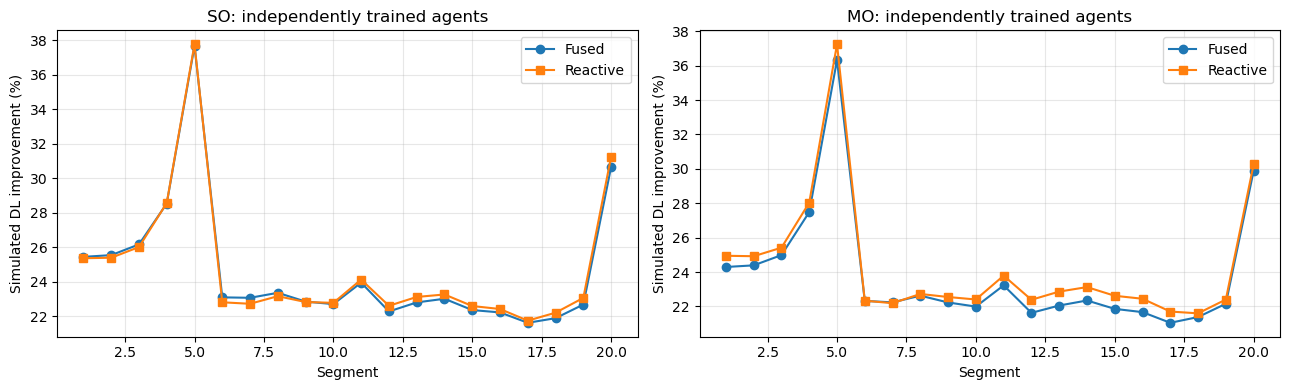

In [10]:
# Optional cross-notebook comparison; only uses saved results.
from scipy import stats
fused_file=DATA_DIR/'fused_segment_results.csv'
if fused_file.exists():
    fused_segment_results=pd.read_csv(fused_file)
    # STAGE 3: analyze recorded Fused and Reactive results; do NOT retrain either policy.
    from scipy import stats
    import matplotlib.pyplot as plt
    both = pd.concat([fused_segment_results,reactive_segment_results],ignore_index=True)
    paired_results = both.pivot(index=['Segment','Start'],columns='Policy',values='DL improvement (%)').reset_index()
    paired_results.columns.name = None
    paired_results['SO difference (pp)'] = paired_results['Fused SO'] - paired_results['Reactive SO']
    paired_results['MO difference (pp)'] = paired_results['Fused MO'] - paired_results['Reactive MO']
    print('PAIRED 20-SEGMENT RESULTS (percentage improvement in simulated DL throughput)')
    print(paired_results.to_string(index=False,float_format=lambda x:f'{x:+.3f}'))
    for objective in ('SO','MO'):
        delta = paired_results[f'{objective} difference (pp)'].to_numpy()
        wins, losses, ties = int((delta>0).sum()),int((delta<0).sum()),int((delta==0).sum())
        print(f'{objective}: fused mean={paired_results[f"Fused {objective}"].mean():.3f}%, '
              f'reactive mean={paired_results[f"Reactive {objective}"].mean():.3f}%, '
              f'fused-reactive={delta.mean():+.3f} percentage points; '
              f'wins/losses/ties={wins}/{losses}/{ties}')
        if not evaluation_overlap:
            print('  Descriptive paired Wilcoxon p:',stats.wilcoxon(delta).pvalue if np.any(delta) else 1.0)
        else:
            print('  No paired significance test: evaluation windows overlap.')
    print('IMPORTANT: all policies trained on the same trace they were evaluated on; results are in-sample for RL.')
    print('IMPORTANT: independent Q-tables and sequential training do not create independent data.')
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    for ax,objective in zip(axes,('SO','MO')):
        ax.plot(paired_results['Segment'],paired_results[f'Fused {objective}'],marker='o',label='Fused')
        ax.plot(paired_results['Segment'],paired_results[f'Reactive {objective}'],marker='s',label='Reactive')
        ax.set(title=f'{objective}: independently trained agents',xlabel='Segment',ylabel='Simulated DL improvement (%)')
        ax.grid(alpha=.3);ax.legend()
    plt.tight_layout();plt.show()
else:
    print("Fused result CSV not present; Reactive evaluation above is complete. Add fused_segment_results.csv for comparison.")


## Ten-seed Q-learning robustness evaluation
Run this section after all preceding cells. The original single-seed analysis remains unchanged. Results are descriptive and in-sample for RL.

In [11]:
# Ten-seed Reactive training and paired Fused–Reactive analysis.
# Execute AFTER the existing Reactive setup cells and AFTER the Fused 10-seed cell.
RL_ROBUSTNESS_SEEDS = [42, 7, 17, 23, 31, 47, 59, 71, 83, 97]
_fused_path = DATA_DIR/'fused_10seed_summary.csv'
_fused_windows_path = DATA_DIR/'fused_10seed_windows.csv'
if not (_fused_path.exists() and _fused_windows_path.exists()):
    raise FileNotFoundError('Run the Fused 10-seed cell first and share its phase1_rl_exports folder.')
fused_seed_results = pd.read_csv(_fused_path)
fused_seed_windows = pd.read_csv(_fused_windows_path)
assert set(fused_seed_results['Seed']) == set(RL_ROBUSTNESS_SEEDS)
assert set(fused_seed_windows['Start']) == set(cv_starts)

_reactive_rows = []
_reactive_windows = []
for _seed in RL_ROBUSTNESS_SEEDS:
    for _objective, _env_cls in [('SO', SOEnvReactive), ('MO', MOEnvReactive)]:
        _env = _env_cls(y_te_aligned, np.zeros_like(y_te_aligned), cov_aligned, lo_rl, hi_rl)
        _agent, _train_rewards = train_policy_independently(_env, seed=int(_seed))
        _windows = evaluate_policy_segments(_agent, _env, f'Reactive {_objective}')
        _windows['Seed'] = int(_seed)
        _reactive_windows.append(_windows)
        _fixed = simulate(_agent, _env, N_SIM, fixed_start=FIXED_START)
        _baseline = y_te_aligned[FIXED_START:FIXED_START + N_SIM] * (hi_rl - lo_rl) + lo_rl
        _fixed_gain = 100 * (_fixed['DL_Mbps_post'].mean() - _baseline.mean()) / max(_baseline.mean(), 1e-9)
        _reactive_rows.append({'Seed': int(_seed), 'Objective': _objective, 'Policy': 'Reactive',
                               'Mean 20-window improvement (%)': float(_windows['DL improvement (%)'].mean()),
                               'Fixed-start improvement (%)': float(_fixed_gain),
                               'Q states': len(_agent.Q)})
        print(f'Reactive {_objective} seed={_seed}: mean 20-window gain={_windows["DL improvement (%)"].mean():.3f}%')

reactive_seed_results = pd.DataFrame(_reactive_rows)
reactive_seed_windows = pd.concat(_reactive_windows, ignore_index=True)
reactive_seed_results.to_csv(DATA_DIR/'reactive_10seed_summary.csv', index=False)
reactive_seed_windows.to_csv(DATA_DIR/'reactive_10seed_windows.csv', index=False)

paired_seed_results = fused_seed_results.merge(reactive_seed_results, on=['Seed','Objective'], suffixes=('_Fused','_Reactive'), validate='one_to_one')
paired_seed_results['Fused-minus-Reactive (pp)'] = paired_seed_results['Mean 20-window improvement (%)_Fused'] - paired_seed_results['Mean 20-window improvement (%)_Reactive']
paired_seed_results['Fixed-start difference (pp)'] = paired_seed_results['Fixed-start improvement (%)_Fused'] - paired_seed_results['Fixed-start improvement (%)_Reactive']
paired_seed_results.to_csv(DATA_DIR/'paired_10seed_results.csv', index=False)

summary_rows=[]
for _objective, _group in paired_seed_results.groupby('Objective'):
    _diff=_group['Fused-minus-Reactive (pp)']
    summary_rows.append({'Objective':_objective, 'N seeds':len(_group),
        'Fused mean (%)':_group['Mean 20-window improvement (%)_Fused'].mean(),
        'Fused SD (%)':_group['Mean 20-window improvement (%)_Fused'].std(ddof=1),
        'Reactive mean (%)':_group['Mean 20-window improvement (%)_Reactive'].mean(),
        'Reactive SD (%)':_group['Mean 20-window improvement (%)_Reactive'].std(ddof=1),
        'Paired difference mean (pp)':_diff.mean(),
        'Paired difference SD (pp)':_diff.std(ddof=1),
        'Fused winning seeds':int((_diff>0).sum())})
seed_summary=pd.DataFrame(summary_rows)
seed_summary.to_csv(DATA_DIR/'paired_10seed_mean_sd.csv',index=False)
print('\nPAIRED 10-SEED RESULTS:')
print(paired_seed_results[['Seed','Objective','Mean 20-window improvement (%)_Fused','Mean 20-window improvement (%)_Reactive','Fused-minus-Reactive (pp)']].to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('\nMEAN AND SAMPLE SD ACROSS TRAINING SEEDS:')
print(seed_summary.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('\nInterpretation: seed-to-seed training variability on ONE in-sample RL trace; overlapping windows are not independent replicates. No unseen-trace generalization is claimed.')


Reactive SO seed=42: mean 20-window gain=24.695%
Reactive MO seed=42: mean 20-window gain=24.300%
Reactive SO seed=7: mean 20-window gain=24.780%
Reactive MO seed=7: mean 20-window gain=24.231%
Reactive SO seed=17: mean 20-window gain=24.482%
Reactive MO seed=17: mean 20-window gain=24.070%
Reactive SO seed=23: mean 20-window gain=25.249%
Reactive MO seed=23: mean 20-window gain=24.322%
Reactive SO seed=31: mean 20-window gain=24.816%
Reactive MO seed=31: mean 20-window gain=24.060%
Reactive SO seed=47: mean 20-window gain=25.366%
Reactive MO seed=47: mean 20-window gain=24.925%
Reactive SO seed=59: mean 20-window gain=25.275%
Reactive MO seed=59: mean 20-window gain=24.627%
Reactive SO seed=71: mean 20-window gain=24.639%
Reactive MO seed=71: mean 20-window gain=23.956%
Reactive SO seed=83: mean 20-window gain=24.438%
Reactive MO seed=83: mean 20-window gain=24.101%
Reactive SO seed=97: mean 20-window gain=25.182%
Reactive MO seed=97: mean 20-window gain=24.562%

PAIRED 10-SEED RESULT